# Beauty & Fashion Stocks: Return and Risk Analyser
**Author:** Apara Bhargava · **Tools:** Python (pandas, NumPy, matplotlib, yfinance) in Google Colab

**Question:** How do Indian and global beauty & fashion stocks compare on return and risk, and does combining them build a better portfolio?

**Stocks (9):**
- **Global:** e.l.f. Beauty, Estée Lauder, Coty, Tapestry (US) · L'Oréal, LVMH (France)
- **India:** Honasa Consumer (Mamaearth), Nykaa (FSN E-Commerce), Trent (Zudio, Westside)
- **Benchmarks (for comparison only):** S&P 500, Nifty 50

**Period:** 8 Nov 2023 (the first full trading day after Honasa listed) to 5 Nov 2026 (closing prices).
**Currency:** all prices converted to **US dollars**, the view of a US-based investor, so returns can be compared fairly.

*How to run: Runtime → Run all. Each step below explains the finance idea first, then the code line by line.*

## Step 1: Install and import the tools
A **library** is ready-made code. We use:
- `yfinance`: downloads share prices from Yahoo Finance
- `pandas`: tables of data (like Excel in Python)
- `numpy`: maths
- `matplotlib`: charts

In [1]:
!pip install yfinance -q          # install yfinance (Colab already has the others)

import yfinance as yf              # 'as yf' gives the library a short nickname
import pandas as pd                # pandas = data tables
import numpy as np                 # numpy = maths (square roots, random numbers)
import matplotlib.pyplot as plt    # matplotlib = charts

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')  # show numbers with 4 decimals
print('Libraries loaded')

Libraries loaded


## Step 2: Settings
We store every choice in one place so it is easy to change.
- **Risk-free rate:** the return you get with no risk. We use the US 10-year Treasury yield, **4.98%** (Federal Reserve H.15, 29 Oct 2026), the same rate as the e.l.f. DCF in Project 1.
- **252** = number of trading days in a year (markets close on weekends and holidays).

In [2]:
START_DATE = '2023-11-08'      # first full trading day after Honasa listed (7 Nov 2023)
END_DATE = '2026-11-06'        # data up to and including 5 Nov 2026 closing prices (end date is excluded)
RISK_FREE = 0.0498             # US 10-year Treasury yield, Fed H.15, 29 Oct 2026
TRADING_DAYS = 252             # trading days in one year

# A dictionary: ticker -> (company name, group, currency)
STOCKS = {
    'ELF':       ('e.l.f. Beauty',   'Global', 'USD'),
    'EL':        ('Estée Lauder',    'Global', 'USD'),
    'COTY':      ('Coty',            'Global', 'USD'),
    'TPR':       ('Tapestry',        'Global', 'USD'),
    'OR.PA':     ("L'Oréal",         'Global', 'EUR'),
    'MC.PA':     ('LVMH',            'Global', 'EUR'),
    'HONASA.NS': ('Honasa (Mamaearth)', 'India', 'INR'),
    'NYKAA.NS':  ('Nykaa',           'India', 'INR'),
    'TRENT.NS':  ('Trent',           'India', 'INR'),
}
BENCHMARKS = {
    '^GSPC': ('S&P 500',  'Benchmark', 'USD'),
    '^NSEI': ('Nifty 50', 'Benchmark', 'INR'),
}
FX = {'INR=X': 'Rupees per 1 US dollar', 'EURUSD=X': 'US dollars per 1 euro'}

ALL = {**STOCKS, **BENCHMARKS}                     # join the two dictionaries
NAMES = {t: v[0] for t, v in ALL.items()}          # ticker -> name, used to label charts
print(len(STOCKS), 'stocks,', len(BENCHMARKS), 'benchmarks')

9 stocks, 2 benchmarks


## Step 3: Download prices
`auto_adjust=True` gives prices **adjusted for dividends and stock splits**, so returns are the true total return.
We also download two exchange rates so we can convert rupees and euros into dollars.

In [3]:
tickers = list(ALL) + list(FX)                      # every symbol we need
raw = yf.download(tickers, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
prices = raw['Close']                               # keep only the closing price

# Check: did every ticker download?
missing = [t for t in tickers if t not in prices.columns or prices[t].dropna().empty]
print('Missing tickers:', missing if missing else 'none')
prices.tail()                                       # show the last 5 rows

Missing tickers: none


Ticker,COTY,EL,ELF,EURUSD=X,HONASA.NS,INR=X,MC.PA,NYKAA.NS,OR.PA,TPR,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,,,
2026-10-30,3.4000,109.2300,111.6900,1.1183,442.1000,95.1524,387.0000,349.3500,436.9500,116.2900,"3,017.3000","7,580.0698","23,053.0996"
2026-11-02,3.4800,104.7700,110.6800,1.1157,452.7500,94.9050,393.6500,353.6500,436.5000,120.7600,"3,046.3999","7,541.3999","23,440.8008"
2026-11-03,3.2900,105.3900,111.5000,1.1192,457.2000,94.7254,401.5000,353.9000,432.7000,121.0200,"3,036.5000","7,568.9199","23,810.8496"
2026-11-04,3.4700,112.0400,113.6300,1.1207,461.7500,94.7484,416.2500,355.5000,444.7500,125.3100,"3,060.0000","7,688.6201","23,960.5996"
2026-11-05,3.9100,107.6500,109.8500,1.1235,NaN,94.5154,NaN,350.3000,NaN,134.1700,"3,055.0000","7,353.7300","24,536.5996"


## Step 4: Clean the data and convert to US dollars
- Indian, French and US markets have **different holidays**, so some days have gaps. `ffill()` fills a gap with the previous day's price (the price did not change because the market was closed).
- **Rupee to dollar:** price in ₹ ÷ (₹ per $1). **Euro to dollar:** price in € × ($ per €1).
- **Split errors:** Yahoo sometimes applies a stock split on the wrong date, creating a fake jump (this happened to Trent on 1 Jan 2026: a fake -33% day, exactly 1/1.5 for its 1.5-for-1 split). The code detects jumps that match a recorded split ratio and corrects the earlier prices.

In [4]:
prices = prices.ffill()                                   # fill holiday gaps with the last price
def fix_split_errors(prices, tickers):
    # Yahoo sometimes applies a stock split on the wrong date, creating a fake one-day jump.
    # If a one-day move matches a split ratio Yahoo has on record, rescale the earlier prices.
    log = []
    for t in tickers:
        if t not in prices.columns: continue
        splits = yf.Ticker(t).splits
        splits = splits[splits != 1] if splits is not None else []
        if len(splits) == 0: continue
        ratio = prices[t] / prices[t].shift(1)                         # today's price / yesterday's
        for f in splits.values:
            for day, x in ratio[(ratio * f - 1).abs() < 0.05].items():    # jump down = 1/split ratio
                prices.loc[prices.index < day, t] = prices.loc[prices.index < day, t] / f
                log.append(f'{t}: {x - 1:+.1%} on {day.date()} matches split ratio {f}: earlier prices divided by {f}')
            for day, x in ratio[(ratio / f - 1).abs() < 0.05].items():          # jump up = split ratio
                prices.loc[prices.index < day, t] = prices.loc[prices.index < day, t] * f
                log.append(f'{t}: {x - 1:+.1%} on {day.date()} matches split ratio {f}: earlier prices multiplied by {f}')
    print('Split corrections:', '\n  ' + '\n  '.join(log) if log else 'none needed')
    return prices
prices = fix_split_errors(prices, list(STOCKS)+list(BENCHMARKS))
fx_inr = prices['INR=X']                                  # rupees per dollar
fx_eur = prices['EURUSD=X']                               # dollars per euro

usd = pd.DataFrame(index=prices.index)                    # empty table with the same dates
for t, (name, group, ccy) in ALL.items():                 # loop over every stock and benchmark
    if t in missing:                                      # skip any ticker that failed to download
        continue
    if ccy == 'USD':
        usd[t] = prices[t]                                # already in dollars
    elif ccy == 'INR':
        usd[t] = prices[t] / fx_inr                       # rupees -> dollars
    elif ccy == 'EUR':
        usd[t] = prices[t] * fx_eur                       # euros -> dollars

usd = usd.dropna()                                        # keep only dates where every price exists
print('From', usd.index[0].date(), 'to', usd.index[-1].date(), '|', len(usd), 'trading days')
usd.tail()

Split corrections: 
  TRENT.NS: -33.0% on 2026-01-01 matches split ratio 1.5: earlier prices divided by 1.5
From 2023-11-08 to 2026-11-05 | 781 trading days


,ELF,EL,COTY,TPR,OR.PA,MC.PA,HONASA.NS,NYKAA.NS,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,
2026-10-30,111.6900,109.2300,3.4000,116.2900,488.6327,432.7746,4.6462,3.6715,31.7102,"7,580.0698",242.2756
2026-11-02,110.6800,104.7700,3.4800,120.7600,486.9967,439.1896,4.7706,3.7264,32.0995,"7,541.3999",246.9923
2026-11-03,111.5000,105.3900,3.2900,121.0200,484.2807,449.3615,4.8266,3.7361,32.0558,"7,568.9199",251.3671
2026-11-04,113.6300,112.0400,3.4700,125.3100,498.4422,466.5015,4.8734,3.7520,32.2961,"7,688.6201",252.8866
2026-11-05,109.8500,107.6500,3.9100,134.1700,499.6742,467.6546,4.8854,3.7063,32.3228,"7,353.7300",259.6042


## Step 4b: Data quality checks
Before trusting any result, check the data:
1. **Did every ticker download?**
2. **Is each price series up to date?** (same last date)
3. **How many gaps were filled?** (exchange holidays are normal; long gaps are not)
4. **Any impossible daily moves?** A move above 25% in a day is flagged: it can be real news or a data error (for example a missed stock split).
5. **Are exchange rates in a sensible range?**
6. **Cross-check with Bloomberg:** the cell prints unadjusted closing prices on 4 dates. Type the Bloomberg closes into `BLOOMBERG` and run again: each pair should match within 1%.

In [5]:
# ===== STEP 4b: Data quality checks =====
issues = []                                                   # we collect any problems here

# 1. Every ticker downloaded?
print('1. Missing tickers:', missing if missing else 'none')
if missing: issues.append(f'missing tickers {missing}')

# 2. Is every series up to date? (last date with a real price, before filling)
raw_close = raw['Close']
last_dates = raw_close.apply(lambda s: s.dropna().index.max())
print('\n2. Last real price date for each ticker:')
print(last_dates.dt.date.to_string())
if (last_dates.max() - last_dates.min()).days > 5:
    issues.append('some tickers stop more than 5 days before others')

# 3. How many days were filled (holidays)?
gaps = raw_close.loc[usd.index].isna().sum()
print('\n3. Days filled with the previous price (holidays):')
print(gaps.to_string())

# 4. Extreme daily moves (possible data errors)
daily = usd.pct_change().dropna()                         # daily returns in US$
big = daily.stack()                                          # one long list: (date, ticker) -> return
big = big[big.abs() > 0.25]                                  # keep only moves above 25%
print('\n4. Daily moves above 25%:', 'none' if big.empty else '')
for (day, t), r in big.items():
    print(f'   {NAMES.get(t, t)} on {day.date()}: {r:+.1%}  <- check this against the news')

# 5. Exchange rates in a sensible range?
fx_ok = fx_inr.between(60, 120).all() and fx_eur.between(0.8, 1.6).all()
print('\n5. Exchange rates in range (60-120 Rs per $, 0.8-1.6 $ per euro):', 'PASS' if fx_ok else 'CHECK')
if not fx_ok: issues.append('exchange rate out of range')

# 6. Cross-check with Bloomberg: unadjusted closes, local currency, on 4 dates
SAMPLE_DATES = ['2023-11-08', '2024-11-08', '2025-11-07', '2026-10-30']
BBG_TICKER = {'ELF': 'ELF US', 'EL': 'EL US', 'COTY': 'COTY US', 'TPR': 'TPR US', 'OR.PA': 'OR FP',
              'MC.PA': 'MC FP', 'HONASA.NS': 'HONASA IN', 'NYKAA.NS': 'NYKAA IN', 'TRENT.NS': 'TRENT IN'}
unadj = yf.download(list(BBG_TICKER), start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Close']
sample = pd.DataFrame({d: unadj.apply(lambda s: s.dropna().asof(pd.Timestamp(d))) for d in SAMPLE_DATES}).T  # last close on or before each date, per ticker
sample.index.name = 'Date'
print('\n6. Unadjusted closing prices (local currency) to compare with Bloomberg HP <GO>:')
display(sample.round(2))

# Type Bloomberg closes here, e.g. ('ELF', '2026-10-30'): 111.69 , then run this cell again
BLOOMBERG = {
}
rows = []
for (t, d), bbg in BLOOMBERG.items():
    ours = sample.loc[d, t]
    diff = ours / bbg - 1
    rows.append({'Ticker': BBG_TICKER[t], 'Date': d, 'Yahoo': ours, 'Bloomberg': bbg,
                 'Difference': f'{diff:+.2%}', 'Status': 'PASS' if abs(diff) <= 0.01 else 'CHECK'})
    if abs(diff) > 0.01: issues.append(f'{t} on {d} differs from Bloomberg by {diff:+.2%}')
if rows: display(pd.DataFrame(rows))
else: print('   No Bloomberg values entered yet.')

print('\nRESULT:', 'ALL CHECKS PASSED' if not issues else 'CHECK: ' + '; '.join(issues))

1. Missing tickers: none

2. Last real price date for each ticker:
Ticker
COTY         2026-11-05
EL           2026-11-05
ELF          2026-11-05
EURUSD=X     2026-11-05
HONASA.NS    2026-11-04
INR=X        2026-11-05
MC.PA        2026-11-04
NYKAA.NS     2026-11-05
OR.PA        2026-11-04
TPR          2026-11-05
TRENT.NS     2026-11-05
^GSPC        2026-11-05
^NSEI        2026-11-05

3. Days filled with the previous price (holidays):
Ticker
COTY         30
EL           30
ELF          30
EURUSD=X      4
HONASA.NS    44
INR=X         4
MC.PA        18
NYKAA.NS     42
OR.PA        18
TPR          30
TRENT.NS     42
^GSPC        30
^NSEI        43

4. Daily moves above 25%: 
   e.l.f. Beauty on 2025-11-06: -35.0%  <- check this against the news

5. Exchange rates in range (60-120 Rs per $, 0.8-1.6 $ per euro): PASS

6. Unadjusted closing prices (local currency) to compare with Bloomberg HP <GO>:


Ticker,COTY,EL,ELF,HONASA.NS,MC.PA,NYKAA.NS,OR.PA,TPR,TRENT.NS
Date,,,,,,,,,
2023-11-08,10.0300,116.6000,98.1400,322.5000,703.5000,149.3500,415.4500,27.4600,"2,452.8500"
2024-11-08,7.1600,63.9000,120.2000,381.4000,598.4000,184.7400,334.7000,52.2200,"6,298.9500"
2025-11-07,3.7500,87.7500,73.7400,273.9500,603.2000,245.8700,354.4500,103.6800,"4,627.3000"
2026-10-30,3.4000,109.2300,111.6900,442.1000,387.0000,349.3500,436.9500,116.2900,"3,017.3000"


   No Bloomberg values entered yet.

RESULT: ALL CHECKS PASSED


## Step 5: Growth of $100
If you had invested **$100** in each stock on the start date, what would it be worth today?
We divide each price by its first price and multiply by 100.

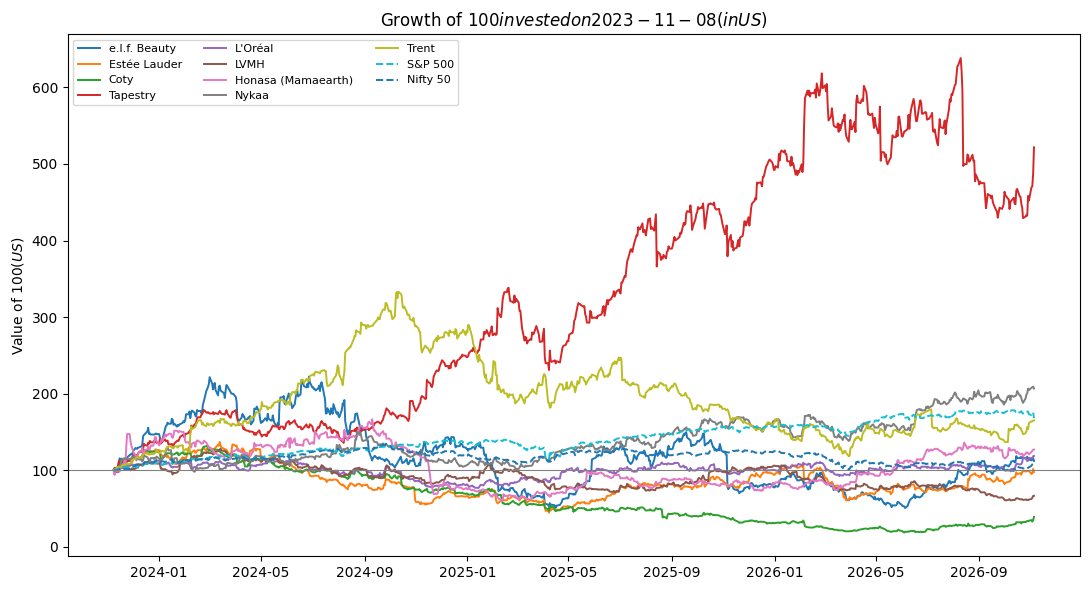

In [6]:
growth = usd / usd.iloc[0] * 100                     # iloc[0] = the first row (start date)

fig, ax = plt.subplots(figsize=(11, 6))               # create an empty chart
for t in growth.columns:
    style = '--' if ALL[t][1] == 'Benchmark' else '-' # dashed lines for benchmarks
    ax.plot(growth.index, growth[t], style, label=NAMES[t], linewidth=1.4)
ax.axhline(100, color='grey', linewidth=0.8)          # the $100 starting line
ax.set_title('Growth of $100 invested on ' + str(usd.index[0].date()) + ' (in US$)')
ax.set_ylabel('Value of $100 (US$)')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig('growth_of_100.png', dpi=150)              # save the chart for GitHub
plt.show()

## Step 6: Daily returns
A **daily return** is the % change in price from one day to the next:

return = today's price ÷ yesterday's price − 1

Everything else (risk, Sharpe, correlation, portfolios) is built from daily returns.

In [7]:
returns = usd.pct_change().dropna()     # pct_change() = % change from the previous row
returns.head()

,ELF,EL,COTY,TPR,OR.PA,MC.PA,HONASA.NS,NYKAA.NS,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,
2023-11-09,0.0133,-0.0110,-0.0259,0.0299,0.0099,0.0169,-0.0631,-0.0122,0.0105,-0.0081,-0.0023
2023-11-10,-0.0438,-0.0049,0.0020,-0.0057,-0.0153,-0.0421,0.0510,0.0150,0.0033,0.0156,0.0003
2023-11-13,0.0230,-0.0089,0.0082,0.0139,0.0031,0.0042,0.0004,0.0113,0.0283,-0.0008,0.0012
2023-11-14,0.0918,0.0799,0.0952,0.0702,0.0251,0.0278,0.0012,0.0012,0.0012,0.0191,0.0012
2023-11-15,0.0659,0.0265,0.0019,0.0121,0.0148,0.0339,-0.0081,0.0195,0.0003,0.0016,0.0146


## Step 7: Return and risk for each stock
| Measure | What it means | Formula |
|---|---|---|
| **Annual return (CAGR)** | Average yearly growth | (end price ÷ start price)^(1 ÷ years) − 1 |
| **Volatility** | How much the price swings: our measure of **risk** | standard deviation of daily returns × √252 |
| **Sharpe ratio** | Extra return per unit of risk (higher = better) | (annual return − risk-free rate) ÷ volatility |
| **Maximum drawdown** | Worst fall from a peak to a low | lowest value of (price ÷ highest price so far − 1) |

In [8]:
def max_drawdown(price_series):
    peak = price_series.cummax()                    # highest price reached so far, each day
    drawdown = price_series / peak - 1              # how far below that peak we are
    return drawdown.min()                           # the worst (most negative) value

years = len(returns) / TRADING_DAYS                 # length of the period in years

rows = []                                           # we collect one row per stock
for t in usd.columns:
    cagr = (usd[t].iloc[-1] / usd[t].iloc[0]) ** (1 / years) - 1
    vol = returns[t].std() * np.sqrt(TRADING_DAYS)
    sharpe = (cagr - RISK_FREE) / vol
    rows.append({'Ticker': t, 'Company': NAMES[t], 'Group': ALL[t][1],
                 'Annual return': cagr, 'Volatility': vol,
                 'Sharpe ratio': sharpe, 'Max drawdown': max_drawdown(usd[t])})

summary = pd.DataFrame(rows).set_index('Ticker').sort_values('Sharpe ratio', ascending=False)
summary.to_csv('stock_summary.csv')                 # save the table
summary

,Company,Group,Annual return,Volatility,Sharpe ratio,Max drawdown
Ticker,,,,,,
TPR,Tapestry,Global,0.7053,0.3901,1.6802,-0.3277
^GSPC,S&P 500,Benchmark,0.1820,0.1487,0.8892,-0.1890
NYKAA.NS,Nykaa,India,0.2641,0.3091,0.6932,-0.3269
TRENT.NS,Trent,India,0.1755,0.3721,0.3377,-0.6453
HONASA.NS,Honasa (Mamaearth),India,0.0799,0.4425,0.0681,-0.6441
OR.PA,L'Oréal,Global,0.0565,0.2503,0.0266,-0.3241
ELF,e.l.f. Beauty,Global,0.0371,0.6333,-0.0201,-0.7726
^NSEI,Nifty 50,Benchmark,0.0347,0.1477,-0.1024,-0.2671
EL,Estée Lauder,Global,-0.0080,0.4624,-0.1250,-0.6759


## Step 8: Risk vs return map
Each dot is one stock. **Top-left is best** (high return, low risk); bottom-right is worst.

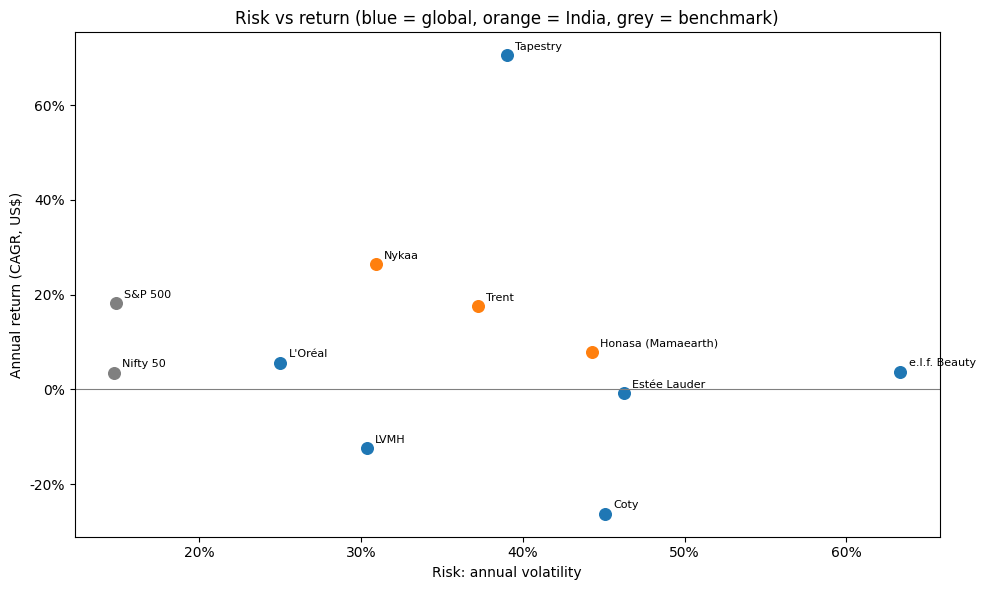

In [9]:
colors = {'Global': 'tab:blue', 'India': 'tab:orange', 'Benchmark': 'grey'}
fig, ax = plt.subplots(figsize=(10, 6))
for t, r in summary.iterrows():                      # iterrows() loops over table rows
    ax.scatter(r['Volatility'], r['Annual return'], color=colors[r['Group']], s=70)
    ax.annotate(r['Company'], (r['Volatility'], r['Annual return']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('Risk: annual volatility')
ax.set_ylabel('Annual return (CAGR, US$)')
ax.set_title('Risk vs return (blue = global, orange = India, grey = benchmark)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))   # show as %
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout(); plt.savefig('risk_return_map.png', dpi=150); plt.show()

## Step 9: Drawdowns over time
How deep did each stock fall from its high, and how long did it stay down?

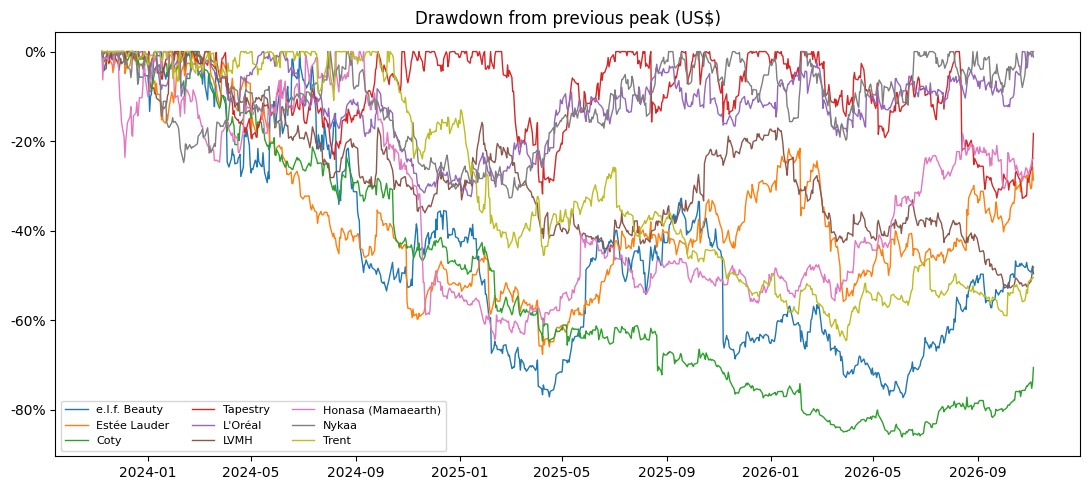

In [10]:
stock_cols = [t for t in usd.columns if ALL[t][1] != 'Benchmark']
dd = usd[stock_cols] / usd[stock_cols].cummax() - 1      # drawdown for every stock, every day

fig, ax = plt.subplots(figsize=(11, 5))
for t in stock_cols:
    ax.plot(dd.index, dd[t], label=NAMES[t], linewidth=1)
ax.set_title('Drawdown from previous peak (US$)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig('drawdowns.png', dpi=150); plt.show()

## Step 10: Correlation heatmap
**Correlation** measures whether two stocks move together:
- **+1** = always move in the same direction
- **0** = no relationship
- **−1** = move in opposite directions

Low correlation is useful: when one stock falls, the other may not, so a mix is **less risky** (this is **diversification**).

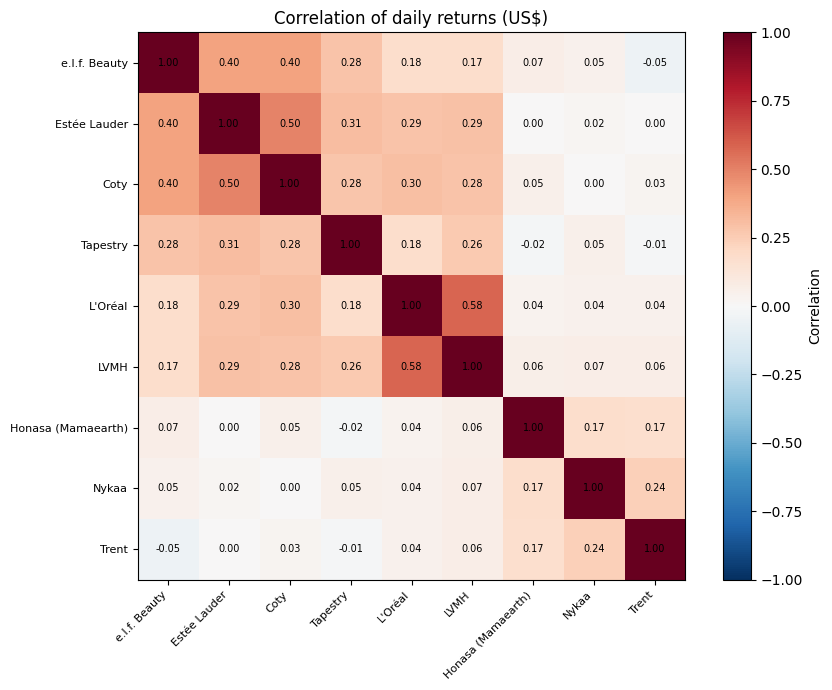

Average correlation within India : 0.2
Average correlation within Global: 0.31
Average correlation India-Global : 0.03


In [11]:
corr = returns[stock_cols].corr()                      # correlation table
labels = [NAMES[t] for t in corr.columns]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)    # red = move together, blue = opposite
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):                           # write each number in its square
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation of daily returns (US$)')
plt.tight_layout(); plt.savefig('correlation_heatmap.png', dpi=150); plt.show()

india = [t for t in stock_cols if ALL[t][1] == 'India']
glob = [t for t in stock_cols if ALL[t][1] == 'Global']
print('Average correlation within India :', round(corr.loc[india, india].values[np.triu_indices(len(india), 1)].mean(), 2))
print('Average correlation within Global:', round(corr.loc[glob, glob].values[np.triu_indices(len(glob), 1)].mean(), 2))
print('Average correlation India-Global :', round(corr.loc[india, glob].values.mean(), 2))

## Step 11: Portfolios
A **portfolio** is a mix of stocks. Its return is the weighted average of the stocks' returns, but its risk is usually **lower** than the average risk, because stocks do not all fall at the same time.

We compare:
1. **Equal-weight India**: 1/3 in each Indian stock
2. **Equal-weight Global**: 1/6 in each global stock
3. **Equal-weight All**: 1/9 in each stock
4. **Optimised (maximum Sharpe)**: we try **10,000 random mixes** and keep the one with the best return per unit of risk
5. **Minimum risk**: the random mix with the lowest volatility

*Formula for portfolio volatility:* √(weights × covariance table × weights) × √252. The **covariance** combines each stock's risk with how it moves with the others.

In [12]:
def portfolio_stats(weights, tickers):
    w = np.array(weights)
    r = returns[tickers]
    daily = r.dot(w)                                       # portfolio daily return = weighted sum
    growth_path = (1 + daily).cumprod()                    # value of $1 over time
    cagr = growth_path.iloc[-1] ** (1 / years) - 1
    vol = np.sqrt(w @ r.cov().values @ w) * np.sqrt(TRADING_DAYS)
    return cagr, vol, (cagr - RISK_FREE) / vol, max_drawdown(growth_path)

# --- 10,000 random portfolios across all 9 stocks ---
np.random.seed(42)                                         # same random numbers every run
n = len(stock_cols)
results = []
for _ in range(10000):
    w = np.random.random(n)                                # random numbers
    w = w / w.sum()                                        # make them add up to 100%
    cagr, vol, sharpe, mdd = portfolio_stats(w, stock_cols)
    results.append((cagr, vol, sharpe, w))

sims = pd.DataFrame(results, columns=['Return', 'Volatility', 'Sharpe', 'Weights'])
best = sims.loc[sims['Sharpe'].idxmax()]                   # highest Sharpe ratio
safest = sims.loc[sims['Volatility'].idxmin()]             # lowest risk

# --- compare the portfolios ---
ports = {
    'Equal-weight India':  ([1/len(india)] * len(india), india),
    'Equal-weight Global': ([1/len(glob)] * len(glob), glob),
    'Equal-weight All':    ([1/n] * n, stock_cols),
    'Optimised (max Sharpe)': (best['Weights'], stock_cols),
    'Minimum risk':        (safest['Weights'], stock_cols),
}
port_rows = []
for name, (w, tk) in ports.items():
    cagr, vol, sharpe, mdd = portfolio_stats(w, tk)
    port_rows.append({'Portfolio': name, 'Annual return': cagr, 'Volatility': vol,
                      'Sharpe ratio': sharpe, 'Max drawdown': mdd})
port_table = pd.DataFrame(port_rows).set_index('Portfolio')
port_table.to_csv('portfolio_summary.csv')
port_table

,Annual return,Volatility,Sharpe ratio,Max drawdown
Portfolio,,,,
Equal-weight India,0.2165,0.2558,0.6516,-0.4251
Equal-weight Global,0.0913,0.2761,0.1502,-0.4541
Equal-weight All,0.1485,0.2068,0.4774,-0.3328
Optimised (max Sharpe),0.3067,0.1873,1.3714,-0.1788
Minimum risk,0.1801,0.1728,0.7542,-0.2539


### Weights of the optimised portfolios

In [13]:
weights = pd.DataFrame({'Max Sharpe': best['Weights'], 'Minimum risk': safest['Weights']},
                       index=[NAMES[t] for t in stock_cols])
weights.to_csv('optimised_weights.csv')
weights.style.format('{:.1%}')

,Max Sharpe,Minimum risk
e.l.f. Beauty,8.4%,3.5%
Estée Lauder,1.4%,4.5%
Coty,0.1%,0.8%
Tapestry,23.2%,6.6%
L'Oréal,24.2%,28.7%
LVMH,2.8%,9.6%
Honasa (Mamaearth),0.3%,7.3%
Nykaa,22.0%,19.4%
Trent,17.6%,19.6%


## Step 12: The efficient frontier
Each grey dot is one random portfolio. The upper-left edge of the cloud is the **efficient frontier**: the best return available for each level of risk.

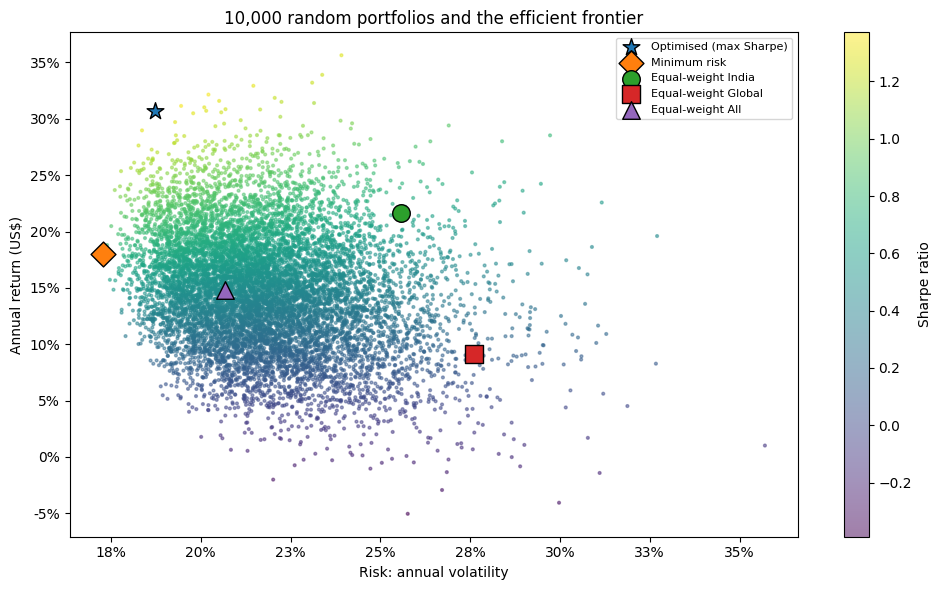

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(sims['Volatility'], sims['Return'], c=sims['Sharpe'], cmap='viridis', s=4, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Sharpe ratio')
for name, marker in [('Optimised (max Sharpe)', '*'), ('Minimum risk', 'D'),
                     ('Equal-weight India', 'o'), ('Equal-weight Global', 's'), ('Equal-weight All', '^')]:
    r = port_table.loc[name]
    ax.scatter(r['Volatility'], r['Annual return'], marker=marker, s=160, edgecolor='black', label=name)
ax.set_xlabel('Risk: annual volatility'); ax.set_ylabel('Annual return (US$)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('10,000 random portfolios and the efficient frontier')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('efficient_frontier.png', dpi=150); plt.show()

## Step 13: Save the results
All tables and charts are saved as files. Step 16 (the last step) downloads them together as one zip file.

In [15]:
# Files are saved here; Step 16 downloads everything as one zip file at the end.
print('Results saved. Download happens in Step 16.')

Results saved. Download happens in Step 16.


## Step 14: Findings
Period: 8 Nov 2023 to 5 Nov 2026 (closing prices), in US dollars.

1. **Only Tapestry beat the market after adjusting for risk:** 70.5% a year, Sharpe 1.68 vs 0.89 for the S&P 500.
2. **e.l.f. was the riskiest stock:** 63% volatility and a 77% fall from its peak, for 3.7% a year.
3. **Indian stocks did better:** Nykaa 26.4% a year, Trent 17.5%, Honasa 8.0%. Equal-weight India returned 21.6% a year vs 9.1% for global. Coty was the worst (-26.2%).
4. **Mixing India and global cut risk by about a fifth:** average India-global correlation 0.03 (global 0.31, India 0.19). The 9-stock mix had 20.7% volatility and a 33% worst fall, vs 25.6% / 43% (India) and 27.6% / 45% (global).
5. **The optimised portfolio** (30.7% a year, Sharpe 1.37) is chosen with hindsight.
6. **Deflated Sharpe Ratio 78%**, below the 95% standard: the best of 10,000 portfolios may be luck.
7. **Currency matters:** Nifty 50 returned 3.5% a year in US$ vs 18.2% for the S&P 500.
8. **The data checks caught a Yahoo error:** Trent's 1.5-for-1 split was applied from 1 Jan 2026, creating a fake -33% day. Confirmed against reported prices and corrected automatically.

## Limitations
- **Past returns do not predict future returns.** The optimised weights are chosen using the same data they are tested on (in-sample), so they look better than they would in real life.
- The period is short (about 3 years), set by Honasa's listing date.
- Converting to US dollars adds currency moves: a weaker rupee lowers Indian returns for a US investor.
- No transaction costs or taxes.
- Random search finds a good portfolio, not the mathematically exact best one.
- Indian markets close before US markets open, so daily India-US correlations are understated.

## Step 15: Is the best portfolio real, or just luck? (Deflated Sharpe Ratio)
I tried 10,000 random portfolios and kept the one with the best Sharpe ratio. If you try enough times, one portfolio will look good by luck alone.
The **Deflated Sharpe Ratio** (Bailey & López de Prado, 2014) calculates the best Sharpe ratio that pure luck would give for that many tries, then gives the **probability that my result beats luck**, also allowing for skew and fat tails in returns.
**Rule:** above 95% = likely real; below 95% = could be luck.

Best portfolio Sharpe (annualised):           1.26
Sharpe expected from luck alone, 10,000 tries: 0.82
Days of data: 780 | skew: -0.11 | kurtosis: 5.33
Probability Sharpe > 0 if we had tried only 1:  98.6%
DEFLATED SHARPE RATIO (allowing for 10,000 tries): 78.1%
Rule: above 95% = likely real skill; below 95% = could be luck


,Luck hurdle (annual Sharpe),Probability result is real
Portfolios tried,,
1,0.00,98.6%
10,0.33,94.7%
100,0.54,89.7%
1000,0.69,84.1%
10000,0.82,78.1%


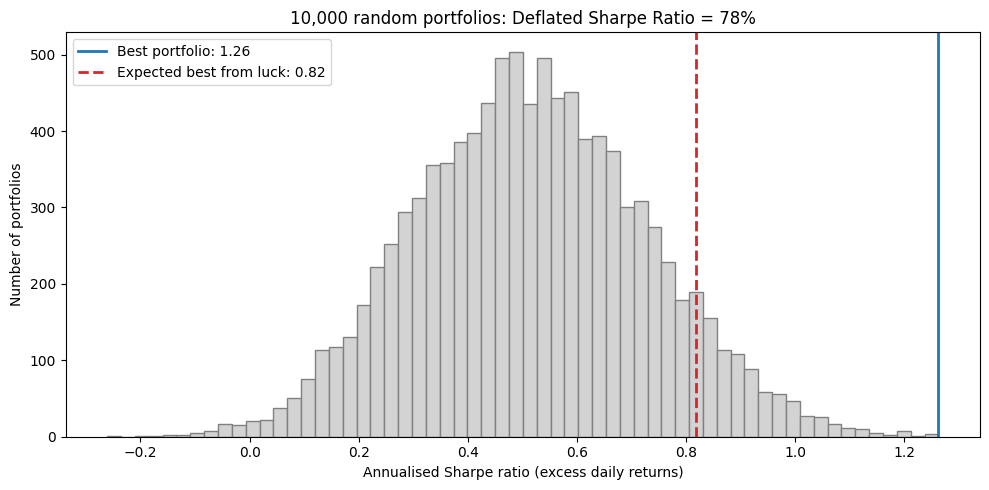

In [16]:
# ===== STEP 15: Is the best portfolio real, or just luck? (Deflated Sharpe Ratio) =====
if 'sims' not in globals():                                # check the earlier steps are still in memory
    raise RuntimeError('Colab has reset. Run Steps 1-12 again first (Runtime > Run before), then this cell.')
from scipy.stats import norm, skew, kurtosis     # statistics tools (normal distribution, skew, kurtosis)

rf_daily = (1 + RISK_FREE) ** (1 / TRADING_DAYS) - 1     # convert the 4.98% yearly risk-free rate to a daily rate

# 1. Rebuild the daily returns of all 10,000 random portfolios
W = np.vstack(sims['Weights'].values)                    # table of weights: 10,000 rows x 9 stocks
port_daily = returns[stock_cols].values @ W.T            # daily return of every portfolio (days x 10,000)
excess = port_daily - rf_daily                           # return above the risk-free rate

# 2. Sharpe ratio of every portfolio, in daily terms (the formula needs daily numbers)
sr_all = excess.mean(axis=0) / excess.std(axis=0, ddof=1)
best_i = sr_all.argmax()                                 # the portfolio with the highest Sharpe
sr_best = sr_all[best_i]
T = excess.shape[0]                                      # number of trading days
x = excess[:, best_i]                                    # daily excess returns of the best portfolio
g3 = skew(x)                                             # skew: are big moves more often down (<0) or up (>0)?
g4 = kurtosis(x, fisher=False)                           # kurtosis: how fat the tails are (normal = 3)

# 3. The two formulas from Bailey & Lopez de Prado (2014)
def expected_max_sharpe(var_sr, n_trials):
    # The best Sharpe you would expect from n_trials portfolios that have NO real skill
    gamma = 0.5772156649                                 # Euler-Mascheroni constant
    return np.sqrt(var_sr) * ((1 - gamma) * norm.ppf(1 - 1 / n_trials)
                              + gamma * norm.ppf(1 - 1 / (n_trials * np.e)))

def prob_sharpe(sr, sr_benchmark, T, g3, g4):
    # Probability that the true Sharpe is above sr_benchmark, given T days, skew and kurtosis
    return norm.cdf((sr - sr_benchmark) * np.sqrt(T - 1)
                    / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2))

var_sr = sr_all.var(ddof=1)                              # how much Sharpe ratios differ across the 10,000 tries
sr0 = expected_max_sharpe(var_sr, len(sr_all))           # "luck" hurdle for 10,000 tries
dsr = prob_sharpe(sr_best, sr0, T, g3, g4)               # Deflated Sharpe Ratio
psr = prob_sharpe(sr_best, 0, T, g3, g4)                 # probability Sharpe > 0, ignoring how many we tried

ann = np.sqrt(TRADING_DAYS)                              # to turn daily Sharpe into yearly Sharpe
print(f'Best portfolio Sharpe (annualised):           {sr_best * ann:.2f}')
print(f'Sharpe expected from luck alone, 10,000 tries: {sr0 * ann:.2f}')
print(f'Days of data: {T} | skew: {g3:.2f} | kurtosis: {g4:.2f}')
print(f'Probability Sharpe > 0 if we had tried only 1:  {psr:.1%}')
print(f'DEFLATED SHARPE RATIO (allowing for 10,000 tries): {dsr:.1%}')
print('Rule: above 95% = likely real skill; below 95% = could be luck')

# 4. How the answer changes with the number of tries
rows = [{'Portfolios tried': 1, 'Luck hurdle (annual Sharpe)': 0.0, 'Probability result is real': psr}]
for n in [10, 100, 1000, 10000]:
    h = expected_max_sharpe(var_sr, n)
    rows.append({'Portfolios tried': n, 'Luck hurdle (annual Sharpe)': h * ann,
                 'Probability result is real': prob_sharpe(sr_best, h, T, g3, g4)})
dsr_table = pd.DataFrame(rows).set_index('Portfolios tried')
dsr_table.to_csv('deflated_sharpe.csv')
display(dsr_table.style.format({'Luck hurdle (annual Sharpe)': '{:.2f}', 'Probability result is real': '{:.1%}'}))

# 5. Chart: all 10,000 Sharpe ratios, the best one, and the luck hurdle
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sr_all * ann, bins=60, color='lightgrey', edgecolor='grey')
ax.axvline(sr_best * ann, color='tab:blue', linewidth=2, label=f'Best portfolio: {sr_best * ann:.2f}')
ax.axvline(sr0 * ann, color='tab:red', linestyle='--', linewidth=2, label=f'Expected best from luck: {sr0 * ann:.2f}')
ax.set_xlabel('Annualised Sharpe ratio (excess daily returns)')
ax.set_ylabel('Number of portfolios')
ax.set_title(f'10,000 random portfolios: Deflated Sharpe Ratio = {dsr:.0%}')
ax.legend()
plt.tight_layout(); plt.savefig('deflated_sharpe.png', dpi=150); plt.show()



## Step 16: Download all results
One zip file with every table and chart. Send it to Claude, and upload the files to GitHub.

In [17]:
!zip -q project3_results.zip *.csv *.png
from google.colab import files
files.download('project3_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>